In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import median_absolute_error
import random
import datetime

import tensorflow as tf
from tensorflow import keras
from tensorflow.python.keras.losses import LossFunctionWrapper
from tensorflow.python.keras.utils import losses_utils
import tensorflow_probability as tfp
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
tfd = tfp.distributions
tf.get_logger().setLevel('ERROR')  # Adjust 'ERROR' as needed

import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

import keras_tuner as kt
import IPython

import os

2023-12-20 10:04:18.968455: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-12-20 10:04:19.657245: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/cuda-11.8/lib64:
2023-12-20 10:04:19.657322: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/cuda-11.8/lib64:
2023-12-20 10:04:19.657328: W tensorflow/compiler/tf2tensorrt/utils/py_uti

In [35]:
def confidence_interval(time_series, quantile):

    mean = tf.reduce_mean(time_series, axis=0)
    standard_deviation = tf.math.reduce_std(time_series, axis=0)

    # (-1, 1, 1, 1) Broadcast std with shape (quantile, timesteps, horizon)
    max_interval = mean + tf.reshape(tfd.Normal(loc=0, scale=1).quantile(quantile), (-1, 1, 1, 1)) * standard_deviation
    min_interval = mean - tf.reshape(tfd.Normal(loc=0, scale=1).quantile(quantile), (-1, 1, 1, 1)) * standard_deviation

    return mean, min_interval, max_interval

def fig_add_trace(fig, y, x, row, col):
    for data, fill, name, color, showlegend in y:
        fig.add_trace(
            go.Scatter(
                name=name,
                x=x,
                y=data,
                fill=fill,
                line=dict(color=color),
                fillcolor=color,
                showlegend=showlegend),
            row=row, col=col)
        

<h2 style="text-align: center; font-size:50px; background-color: #428bca; color:#FFFFFF"> Dataset preprocessing </h2><a id=e></a>
<hr>

In [3]:
class DataSet:
    """
    Preprocessing.
    """
    def __init__(self, horizon, back_horizon):
        self.horizon = horizon
        self.back_horizon = back_horizon

    def preprocessing(self, y, date, train_size=0.7, val_size=0.2):

        y = y.copy().astype('float')

        train = y[:int(train_size*len(y))]
        val = y[int(train_size*len(y))-self.back_horizon:int((train_size+val_size)*len(y))]
        test = y[int((train_size+val_size)*len(y))-self.back_horizon:]
        train_date = date[:int(train_size*len(y))]
        val_date = date[int(train_size*len(y))-self.back_horizon:int((train_size+val_size)*len(y))]
        test_date = date[int((train_size+val_size)*len(y))-self.back_horizon:]

        # Training set
        self.X_train, self.y_train, self.train_date = self.create_sequences(train,
                                                                            train,
                                                                            train_date,
                                                                            self.horizon,
                                                                            self.back_horizon)
        # Validation set
        self.X_val, self.y_val, self.val_date = self.create_sequences(val,
                                                                      val,
                                                                      val_date,
                                                                      self.horizon,
                                                                      self.back_horizon)
        # Testing set
        self.X_test, self.y_test, self.test_date = self.create_sequences(test,
                                                                         test,
                                                                         test_date,
                                                                         self.horizon,
                                                                         self.back_horizon)

        # training on all database
        self.X_train_all, self.y_train_all, self.train_all_date = self.create_sequences(y,
                                                                                        y,
                                                                                        date,
                                                                                        self.horizon,
                                                                                        self.back_horizon)

    @staticmethod
    def create_sequences(X, y, d, horizon, time_steps):
        Xs, ys, ds = [], [], []
        for col in range(X.shape[1]):
            for i in range(0, len(X)-time_steps-horizon, 1):
                Xs.append(X[i:(i+time_steps), col])
                ys.append(y[(i+time_steps):(i+time_steps+horizon), col])
                ds.append(d[(i+time_steps):(i+time_steps+horizon)])

        return np.array(Xs), np.array(ys), np.array(ds)

In [4]:
import yfinance as yf
ticker_symbol = "AAPL"
stock_data = yf.download(ticker_symbol, end="2023-12-15")
stock_data['Date'] = stock_data.index
stock_data = stock_data.reset_index(drop=True)
stock_data

[*********************100%%**********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume,Date
0,0.128348,0.128906,0.128348,0.128348,0.099319,469033600,1980-12-12
1,0.122210,0.122210,0.121652,0.121652,0.094137,175884800,1980-12-15
2,0.113281,0.113281,0.112723,0.112723,0.087228,105728000,1980-12-16
3,0.115513,0.116071,0.115513,0.115513,0.089387,86441600,1980-12-17
4,0.118862,0.119420,0.118862,0.118862,0.091978,73449600,1980-12-18
...,...,...,...,...,...,...,...
10838,194.199997,195.990005,193.669998,195.710007,195.710007,53377300,2023-12-08
10839,193.110001,193.490005,191.419998,193.179993,193.179993,60943700,2023-12-11
10840,193.080002,194.720001,191.720001,194.710007,194.710007,52696900,2023-12-12
10841,195.089996,198.000000,194.850006,197.960007,197.960007,70404200,2023-12-13


In [5]:
stock_date = stock_data['Date']

In [6]:
stock_data = stock_data.drop(columns=['Volume'])

In [7]:
back_horizon = 3 * 52
horizon = 52
stock_data_new = stock_data.drop(columns='Date')

dataset = DataSet(horizon, back_horizon)
dataset.preprocessing(stock_data_new.values, stock_date, train_size=0.6, val_size=0.2)

<h2 style="text-align: center; font-size:50px; background-color: #428bca; color:#FFFFFF"> Tune & Train LSTM</h2><a id=e></a>
<hr>

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
import keras_tuner as kt
from tensorflow.keras.losses import MeanSquaredError


In [9]:
def lstm_model_builder(hp_l):
    hp_units = hp_l.Int('units', min_value=32, max_value=512, step=32)
    hp_multi = hp_l.Boolean('multi')
    
    model = Sequential()
    model.add(LSTM(units= hp_units, return_sequences=hp_multi, input_shape=(156, 1)))
    if hp_multi:
        model.add(LSTM(units=hp_units))
    model.add(Dense(horizon))
    model.compile(loss=MeanSquaredError(), optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                         metrics=[tf.keras.metrics.MeanAbsoluteError()])
    return model

    

from keras_tuner.tuners import RandomSearch

tuner_lstm = kt.Hyperband(lstm_model_builder,
                     objective = 'val_mean_absolute_error',
                     max_epochs = 10,
                     factor = 3,
                     directory = 'my_dir',
                     project_name = 'Time Series LSTM')

class ClearTrainingOutput(tf.keras.callbacks.Callback):
    def on_train_end(*args, **kwargs):
        IPython.display.clear_output(wait = True)

tuner_lstm.search(dataset.X_train, dataset.y_train, epochs = 20,
             validation_data = (dataset.X_val, dataset.y_val), callbacks = [ClearTrainingOutput()])

In [10]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = "time_series_lstm_checkpoint/cp.ckpt"
checkpoint_dir = os.path.dirname(checkpoint_path)
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

best_hps_lstm = tuner_lstm.get_best_hyperparameters(num_trials = 1)[0]

model_lstm = tuner_lstm.hypermodel.build(best_hps_lstm)
model_lstm.build((None, back_horizon))
model_lstm.summary()

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.001)
es_cb = EarlyStopping(monitor='val_loss', min_delta=0,  patience=10, verbose=0, mode='auto', restore_best_weights=True)

history_lstm = model_lstm.fit(dataset.X_train, dataset.y_train, batch_size=64, epochs=100,
                    callbacks = [reduce_lr, es_cb, checkpoint_callback], validation_data = (dataset.X_val, dataset.y_val))


2023-12-20 10:04:31.576737: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2023-12-20 10:04:31.598579: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2023-12-20 10:04:31.599020: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:981] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2023-12-20 10:04:31.599834: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorF

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 384)               592896    
                                                                 
 dense (Dense)               (None, 52)                20020     
                                                                 
Total params: 612,916
Trainable params: 612,916
Non-trainable params: 0
_________________________________________________________________
Epoch 1/100


2023-12-20 10:04:34.746957: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:428] Loaded cuDNN version 8700
2023-12-20 10:04:34.890868: I tensorflow/compiler/xla/service/service.cc:173] XLA service 0x7fee5c13a6a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2023-12-20 10:04:34.890905: I tensorflow/compiler/xla/service/service.cc:181]   StreamExecutor device (0): NVIDIA GeForce RTX 2070, Compute Capability 7.5
2023-12-20 10:04:34.890910: I tensorflow/compiler/xla/service/service.cc:181]   StreamExecutor device (1): NVIDIA GeForce RTX 2070, Compute Capability 7.5
2023-12-20 10:04:34.894888: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


  4/492 [..............................] - ETA: 9s - loss: 0.2904 - mean_absolute_error: 0.3766   

2023-12-20 10:04:35.008183: I tensorflow/compiler/jit/xla_compilation_cache.cc:477] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


489/492 [============================>.] - ETA: 0s - loss: 0.0153 - mean_absolute_error: 0.0643
Epoch 1: val_loss improved from inf to 113.66512, saving model to time_series_lstm_checkpoint/cp.ckpt
492/492 [==============================] - 12s 19ms/step - loss: 0.0153 - mean_absolute_error: 0.0642 - val_loss: 113.6651 - val_mean_absolute_error: 8.2394 - lr: 0.0010
Epoch 2/100
489/492 [============================>.] - ETA: 0s - loss: 0.0091 - mean_absolute_error: 0.0531
Epoch 2: val_loss improved from 113.66512 to 99.93665, saving model to time_series_lstm_checkpoint/cp.ckpt
492/492 [==============================] - 9s 18ms/step - loss: 0.0091 - mean_absolute_error: 0.0531 - val_loss: 99.9367 - val_mean_absolute_error: 7.6609 - lr: 0.0010
Epoch 3/100
489/492 [============================>.] - ETA: 0s - loss: 0.0088 - mean_absolute_error: 0.0525
Epoch 3: val_loss improved from 99.93665 to 89.79399, saving model to time_series_lstm_checkpoint/cp.ckpt
492/492 [==========================

In [11]:
model_lstm_json = model_lstm.to_json()
with open("time_series_lstm_checkpoint/model_architecture.json", "w") as json_file:
    json_file.write(model_lstm_json)

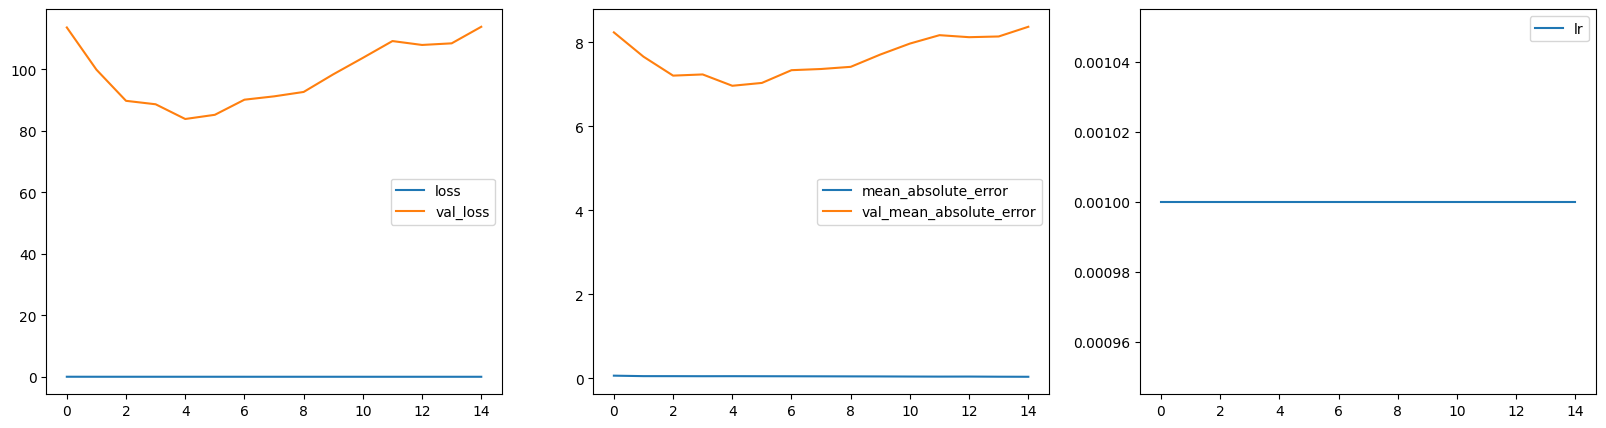

In [12]:
fig = plt.figure(figsize=(20,5))

ax = plt.subplot(131)

epochs = [i for i in range(len(history_lstm.history['loss']))]
ax.plot(epochs, history_lstm.history['loss'], label='loss')
ax.plot(epochs, history_lstm.history['val_loss'], label='val_loss')
plt.legend()

ax = plt.subplot(132)
ax.plot(epochs, history_lstm.history['mean_absolute_error'], label='mean_absolute_error')
ax.plot(epochs, history_lstm.history['val_mean_absolute_error'], label='val_mean_absolute_error')
plt.legend()

ax = plt.subplot(133)
ax.plot(epochs, history_lstm.history['lr'], label='lr')
b = plt.legend()

In [46]:
y_true = dataset.y_test
date_outputs = np.apply_along_axis(lambda x: pd.to_datetime(x, format='%Y-%M-%d'), -1, dataset.test_date)
date = pd.to_datetime(date_outputs[0])

results_lstm = model_lstm.predict(dataset.X_test)
y_pred_mean, y_pred_min_interval, y_pred_max_interval = confidence_interval(results_lstm, [0.99])



331/331 [==============================] - 2s 5ms/step


In [47]:
fig = make_subplots(
        subplot_titles=['True Vs Predicted','Trend','Seasonality', 'Overall trend', 'Overall seasonality'],
        rows=1, cols=1,
        vertical_spacing=0.1,
        horizontal_spacing=0.05,
        specs=[[{"type": "scatter"}]])

# fig.add_trace(
#             go.Scatter(
#                 name= "Y_true",
#                 x=date,
#                 y=y_true[0],
#                 fill='none',
#                 line=dict(color='green'),
#                 fillcolor='green',
#                 showlegend=True),
#             row=1, col=1)
        

# fig.add_trace(
#             go.Scatter(
#                 name= "Y_pred_mean",
#                 x=date,
#                 y=y_pred_mean,
#                 fill='none',
#                 line=dict(color='darkorange'),
#                 fillcolor='darkorange',
#                 showlegend=True),
#             row=1, col=1)

# fig.add_trace(
#             go.Scatter(
#                 name= "Prediction interval",
#                 x=date,
#                 y=y_pred_min_interval[0, 0, 0],
#                 fill='none',
#                 line=dict(color='rgba(255, 0, 0, 0.2)'),
#                 fillcolor='rgba(255, 0, 0, 0.2)',
#                 showlegend=True),
#             row=1, col=1)

# fig.add_trace(
#             go.Scatter(
#                 name= "Prediction interval",
#                 x=date,
#                 y=y_pred_max_interval[0, 0, 0],
#                 fill='tonextx',
#                 line=dict(color='rgba(255, 0, 0, 0.2)'),
#                 fillcolor='rgba(255, 0, 0, 0.2)',
#                 showlegend=True),
#             row=1, col=1)


# fig1.add_trace(
#             go.Scatter(
#                 name="y_true",
#                 x=date_outputs,
#                 y=y_true[0],
#                 line=dict(color="green")),
#             row=1, col=1
#         )
# Trace mean
fig_add_trace(fig, zip([y_pred_min_interval[0, 0, 0], y_pred_max_interval[0, 0, 0],
                       y_true[0], y_pred_mean],
                      ['none', 'tonextx', 'none', 'none'],
                      ['Prediction interval', 'Prediction interval', 'True', 'Prediction Mean'],
                      ['rgba(255, 0, 0, 0.2)', 'rgba(255, 0, 0, 0.2)', 'green', 'darkorange'],
                      [False, True, True, True]), date, row=1, col=1)
fig.show()

<h2 style="text-align: center; font-size:50px; background-color: #428bca; color:#FFFFFF"> Load LSTM</h2><a id=e></a>
<hr>

In [48]:
from tensorflow.keras.models import model_from_json

with tf.device('/CPU:0'):
    with open('time_series_lstm_checkpoint/model_architecture.json', 'r') as json_file:
        loaded_model_json = json_file.read()
    model_lstm = model_from_json(loaded_model_json)

    model_lstm.load_weights("time_series_lstm_checkpoint/cp.ckpt")
    
model_lstm.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 384)               592896    
                                                                 
 dense (Dense)               (None, 52)                20020     
                                                                 
Total params: 612,916
Trainable params: 612,916
Non-trainable params: 0
_________________________________________________________________


In [52]:
results = model_lstm.predict(stock_data_new.iloc[-156:].T.values.astype('float'))
date_forecasting = np.expand_dims(pd.date_range(stock_date.iloc[-1], stock_date.iloc[-1] + pd.Timedelta(52, 'D'), freq='D'), axis=0)
y_pred_mean, y_pred_min_interval, y_pred_max_interval = confidence_interval(results, [0.99])


1/1 [==============================] - 0s 20ms/step


In [53]:
y_pred_mean, y_pred_min_interval, y_pred_max_interval

(<tf.Tensor: shape=(52,), dtype=float32, numpy=
 array([10.797852 , 11.39306  , 11.759069 , 11.342212 , 11.0261   ,
        10.325633 , 10.4008875, 10.424067 , 10.089411 , 11.367814 ,
        10.341295 , 10.804556 , 11.218822 , 10.27166  , 10.36571  ,
        11.092398 ,  9.33181  , 10.561571 , 11.090719 , 11.279312 ,
        10.278829 , 10.866021 , 11.476751 ,  9.30855  , 10.117082 ,
        11.379482 , 10.944584 , 10.229792 , 11.23139  , 10.606688 ,
        11.211356 , 10.563157 , 10.908513 , 12.074339 , 10.387415 ,
        11.089201 ,  9.559301 ,  9.6461315,  9.617745 ,  9.403641 ,
         9.558491 ,  9.614962 ,  8.697601 ,  9.63131  ,  9.39825  ,
         8.092928 ,  8.836927 ,  9.535395 ,  8.08522  ,  8.713934 ,
         8.162064 ,  8.741611 ], dtype=float32)>,
 <tf.Tensor: shape=(1, 1, 1, 52), dtype=float32, numpy=
 array([[[[10.79313 , 11.389887, 11.757548, 11.33806 , 11.018198,
           10.319935, 10.398216, 10.421119, 10.082328, 11.36502 ,
           10.336295, 10.798322, 1

In [50]:
fig = make_subplots(
        subplot_titles=['True Vs Predicted','Trend','Seasonality', 'Overall trend', 'Overall seasonality'],
        rows=1, cols=1,
        vertical_spacing=0.1,
        horizontal_spacing=0.05,
        specs=[[{"type": "scatter"}]])

# Trace mean
fig_add_trace(fig, zip([y_pred_min_interval[0, 0, 0], y_pred_max_interval[0, 0, 0],
                       y_true[0], y_pred_mean],
                      ['none', 'tonextx', 'none', 'none'],
                      ['Prediction interval', 'Prediction interval', 'True', 'Prediction Mean'],
                      ['rgba(255, 0, 0, 0.2)', 'rgba(255, 0, 0, 0.2)', 'green', 'darkorange'],
                      [False, True, True, True]), [i for i in range(52)], row=1, col=1)

    
fig.show()

In [ ]:
date_forecasting